# Deep Learning, Phase 3 (Sequential Models), Day 5: Forecasting Project, Part 1: Data and Baselines
Today we prepare the real forecasting project and set the score that Day 6's LSTM/GRU has to beat. **No neural network today.**

1. Load and look at the data (trend, seasonality)  2. Split **by time** and scale correctly  3. Sliding windows without leakage  4. Baselines  5. Walk-forward evaluation  6. The stock-price warning (random walk)  7. Optional: a real stock with `yfinance`

**Dataset:** monthly airline passengers 1949 to 1960 (144 values). It has a real **trend** and a real **seasonal pattern**, so a model can actually learn something, unlike daily stock prices (see section 6). Stock prices are kept as a second experiment.

**Why baselines first?** A model's error means nothing alone. "MAE 25 passengers" is good or bad only compared with a simple rule. If the LSTM cannot beat the baselines, we must say so.


In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit
sns.set_theme(style='whitegrid')
np.random.seed(42)

## 1. Load and look at the data

(144,) | 1949-01-01 to 1960-12-01
Missing values: 0


,passengers
date,
1949-01-01,112.0
1949-02-01,118.0
1949-03-01,132.0
1949-04-01,129.0
1949-05-01,121.0


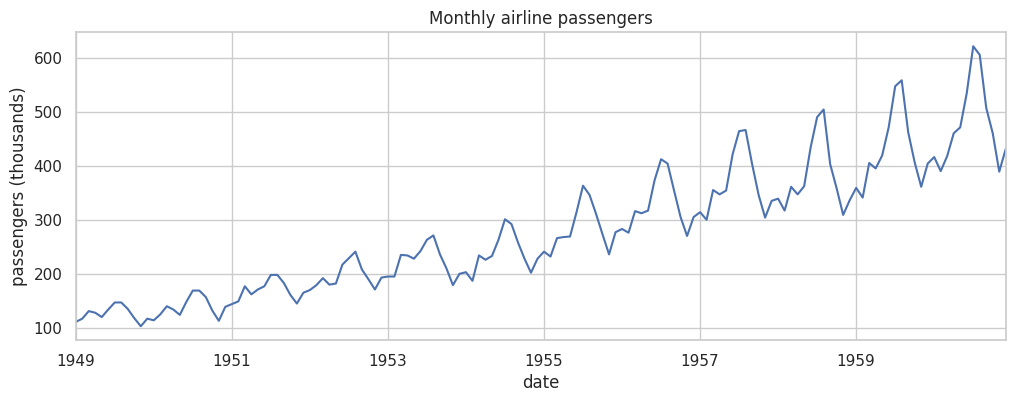

In [ ]:
df = sns.load_dataset('flights')                    # monthly airline passengers (built into seaborn, downloads automatically)
df['date'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str), format='%Y-%b')
series = df.set_index('date')['passengers'].astype(float)
print(series.shape, '|', series.index[0].date(), 'to', series.index[-1].date()); print('Missing values:', series.isna().sum()); display(series.head())
plt.figure(figsize=(12, 4)); series.plot(); plt.ylabel('passengers (thousands)'); plt.title('Monthly airline passengers'); plt.show()

**Trend and seasonality.** The 12-month rolling mean shows the **trend** (steadily rising). Averaging by calendar month shows the **seasonality** (a peak in summer every year).

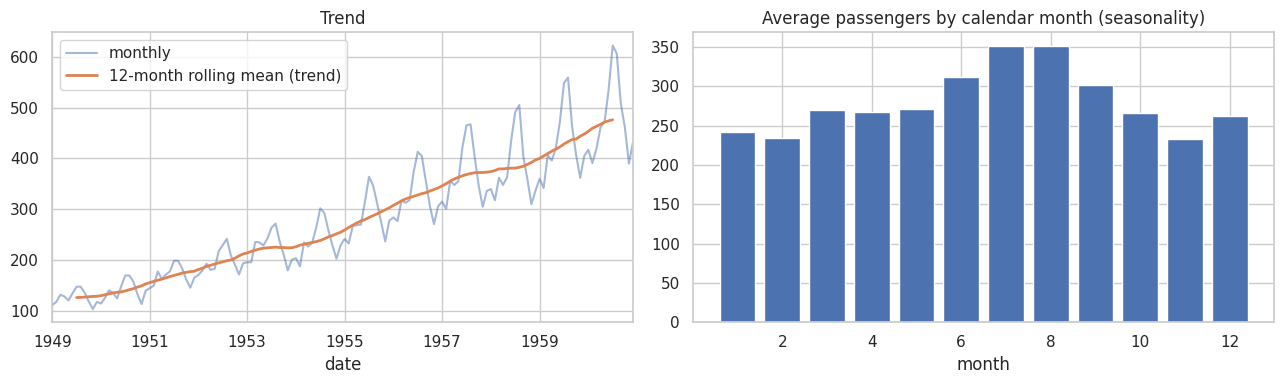

date,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
mean,126.7,139.7,170.2,197.0,225.0,238.9,284.0,328.2,368.4,381.0,428.3,476.2
std,13.7,19.1,18.4,23.0,28.5,34.9,42.1,47.9,57.9,64.5,69.8,77.7


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
series.plot(ax=ax[0], alpha=.5, label='monthly'); series.rolling(12, center=True).mean().plot(ax=ax[0], lw=2, label='12-month rolling mean (trend)'); ax[0].legend(); ax[0].set_title('Trend')
seasonal = series.groupby(series.index.month).mean(); ax[1].bar(seasonal.index, seasonal.values); ax[1].set(title='Average passengers by calendar month (seasonality)', xlabel='month'); plt.tight_layout(); plt.show()
yearly = series.groupby(series.index.year).agg(['mean', 'std']).round(1); display(yearly.T)


## 2. Split by time and scale with training statistics only
- **Never shuffle** a time series before splitting: the future must not be used to predict the past.
- Train = first 96 months (1949 to 1956), validation = next 24 (1957 to 1958), test = last 24 (1959 to 1960).
- The scaler (mean and standard deviation) uses the **training part only**.

train 96 (1949-01-01 to 1956-12-01) | validation 24 (1957-01-01 to 1958-12-01) | test 24 (1959-01-01 to 1960-12-01)
training max = 413, validation max = 505, test max = 622


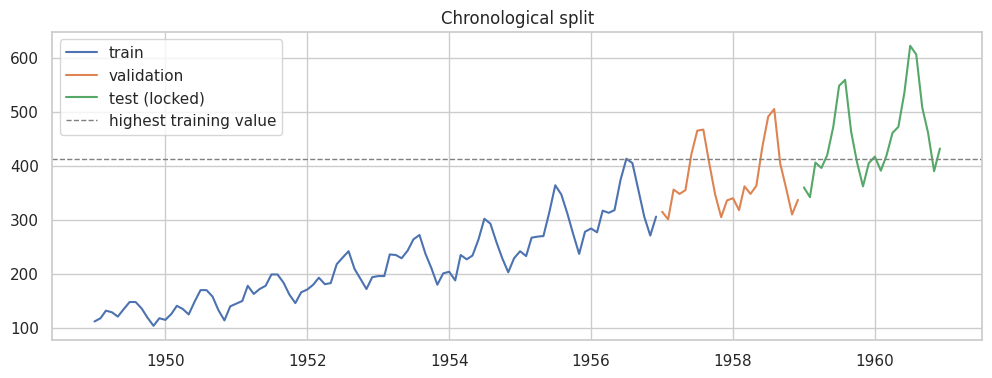

In [ ]:
n_tr, n_va = 96, 24; n_te = len(series) - n_tr - n_va
vals = series.values
mu, sd = vals[:n_tr].mean(), vals[:n_tr].std()                  # statistics from the TRAINING part only
scaled = (vals - mu) / sd
print(f'train {n_tr} ({series.index[0].date()} to {series.index[n_tr-1].date()}) | validation {n_va} ({series.index[n_tr].date()} to {series.index[n_tr+n_va-1].date()}) | test {n_te} ({series.index[n_tr+n_va].date()} to {series.index[-1].date()})')
print(f'training max = {vals[:n_tr].max():.0f}, validation max = {vals[n_tr:n_tr+n_va].max():.0f}, test max = {vals[n_tr+n_va:].max():.0f}')
plt.figure(figsize=(12, 4)); plt.plot(series.index[:n_tr], vals[:n_tr], label='train'); plt.plot(series.index[n_tr:n_tr+n_va], vals[n_tr:n_tr+n_va], label='validation'); plt.plot(series.index[n_tr+n_va:], vals[n_tr+n_va:], label='test (locked)')
plt.axhline(vals[:n_tr].max(), color='grey', ls='--', lw=1, label='highest training value'); plt.legend(); plt.title('Chronological split'); plt.show()

**Important observation:** the validation and test passengers are **higher than anything in the training data** (see the dashed line). A model must predict values it has never seen. Neural networks are usually bad at this (they tend to stay inside the range they saw), while simple rules like "same as last year" do not care. Keep this in mind for Day 6.

## 3. Sliding windows without leakage
Input: the last `K = 12` months (one full season). Target: the next month.

A **window** may take its inputs from the previous split (the first validation target uses the last 12 training months as input). That is not leakage, because those values are in the **past**. What matters is that the **target** lies inside its own split.

In [ ]:
K = 12
def windows(start, end):                              # targets with index in [start, end); inputs = the K values before each target
    X = np.array([scaled[i - K:i] for i in range(start, end)]); y = scaled[start:end]; return X, y
Xtr, ytr = windows(K, n_tr); Xva, yva = windows(n_tr, n_tr + n_va); Xte, yte = windows(n_tr + n_va, len(series))
print('train', Xtr.shape, '| validation', Xva.shape, '| test (locked)', Xte.shape)
inv = lambda a: a * sd + mu                           # back to passengers, so errors are easy to read
dates_va, dates_te = series.index[n_tr:n_tr + n_va], series.index[n_tr + n_va:]

train (84, 12) | validation (24, 12) | test (locked) (24, 12)


## 4. Baselines
All errors are in **passengers (thousands)**, after converting back from the scaled values.
- **Naive:** next month = this month.
- **Moving average (3 months):** the mean of the last 3 months.
- **Seasonal naive:** next month = the same month **last year**. For seasonal data this is the baseline to beat.
- **Linear regression** on the last 12 months, fitted on the training windows only.

Metrics: **MAE** (average error), **RMSE** (punishes big errors more), and **MAPE** (average percentage error, easy to explain).

In [ ]:
def metrics(y_true, y_pred):
    e = y_true - y_pred; return {'MAE': np.abs(e).mean(), 'RMSE': np.sqrt((e ** 2).mean()), 'MAPE %': 100 * np.abs(e / y_true).mean()}

lin = LinearRegression().fit(Xtr, ytr)
def baseline_preds(X):                                # all return scaled predictions
    return {'Naive (last month)': X[:, -1], 'Moving average (3)': X[:, -3:].mean(1), 'Seasonal naive (same month last year)': X[:, 0], 'Linear regression (last 12)': lin.predict(X)}

pv, pt = baseline_preds(Xva), baseline_preds(Xte)
tab_val = pd.DataFrame({k: metrics(inv(yva), inv(v)) for k, v in pv.items()}).T
tab_test = pd.DataFrame({k: metrics(inv(yte), inv(v)) for k, v in pt.items()}).T
print('VALIDATION (used for choosing models)'); display(tab_val.round(2)); print('TEST (baseline scores to beat; do not tune anything on these)'); display(tab_test.round(2))

VALIDATION (used for choosing models)


,MAE,RMSE,MAPE %
Naive (last month),35.88,43.98,9.51
Moving average (3),51.92,63.58,13.61
Seasonal naive (same month last year),26.38,31.70,6.95
Linear regression (last 12),18.97,24.07,5.21


TEST (baseline scores to beat; do not tune anything on these)


,MAE,RMSE,MAPE %
Naive (last month),44.21,51.78,9.73
Moving average (3),62.32,75.01,13.51
Seasonal naive (same month last year),47.58,49.99,10.52
Linear regression (last 12),13.49,17.28,3.12


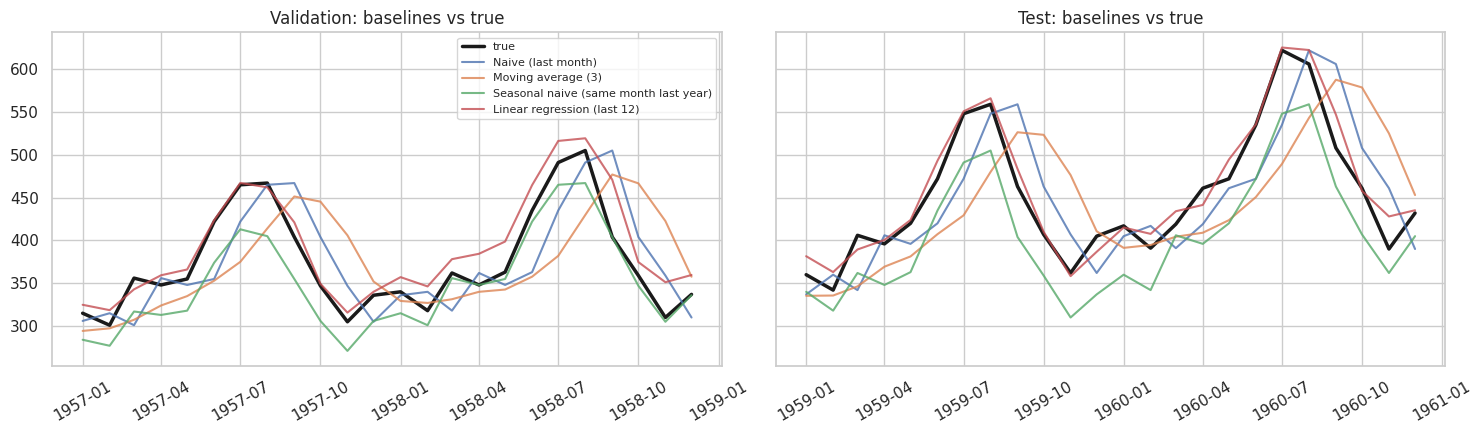

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for a, d, y, p, title in [(ax[0], dates_va, yva, pv, 'Validation'), (ax[1], dates_te, yte, pt, 'Test')]:
    a.plot(d, inv(y), 'k', lw=2.5, label='true')
    for k, v in p.items(): a.plot(d, inv(v), alpha=.8, label=k)
    a.set_title(title + ': baselines vs true'); a.tick_params(axis='x', rotation=30)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()



## 5. Walk-forward evaluation
One validation period can be lucky. **Walk-forward** (expanding-window) evaluation trains on the past and tests on the next block, then moves forward. `TimeSeriesSplit` does exactly this: the training part always comes **before** the test part.

In [ ]:
Xall, yall = windows(K, n_tr + n_va); rows = []                # all windows whose target is in train + validation (the test stays locked)
for fold, (a, b) in enumerate(TimeSeriesSplit(n_splits=5, test_size=12).split(Xall), 1):
    m = LinearRegression().fit(Xall[a], yall[a]); res = {'fold': fold, 'train windows': len(a), 'test targets': f'{series.index[K + b[0]].date()} to {series.index[K + b[-1]].date()}'}
    res['seasonal naive MAE'] = metrics(inv(yall[b]), inv(Xall[b][:, 0]))['MAE']; res['naive MAE'] = metrics(inv(yall[b]), inv(Xall[b][:, -1]))['MAE']; res['linear MAE'] = metrics(inv(yall[b]), inv(m.predict(Xall[b])))['MAE']; rows.append(res)
wf = pd.DataFrame(rows).set_index('fold'); display(wf.round(2)); print('Mean MAE over folds:'); display(wf[['naive MAE', 'seasonal naive MAE', 'linear MAE']].mean().round(2))

,train windows,test targets,seasonal naive MAE,naive MAE,linear MAE
fold,,,,,
1,48,1954-01-01 to 1954-12-01,16.75,22.83,17.05
2,60,1955-01-01 to 1955-12-01,45.08,26.75,17.38
3,72,1956-01-01 to 1956-12-01,44.25,27.83,8.55
4,84,1957-01-01 to 1957-12-01,40.17,33.17,8.84
5,96,1958-01-01 to 1958-12-01,12.58,38.58,26.82


Mean MAE over folds:


,0
naive MAE,29.83
seasonal naive MAE,31.77
linear MAE,15.73




## 6. The stock-price warning
Daily stock prices are close to a **random walk**: tomorrow = today + a random surprise. If that is true, nothing can predict the surprise, so the naive rule "tomorrow = today" is about as good as it gets. We can see this with a **simulated** random walk (no internet needed):

In [ ]:
rng = np.random.default_rng(0); price = 100 * np.exp(np.cumsum(0.01 * rng.normal(size=1500)))        # simulated 'stock': pure random walk, 1500 days
def baselines_for(values, K=20, frac=(0.70, 0.15)):
    n = len(values); a, b = int(n * frac[0]), int(n * (frac[0] + frac[1])); m_, s_ = values[:a].mean(), values[:a].std(); z = (values - m_) / s_
    w = lambda lo, hi: (np.array([z[i - K:i] for i in range(lo, hi)]), z[lo:hi]); Xa, ya = w(K, a); Xb, yb = w(a, b)
    reg = LinearRegression().fit(Xa, ya); inv_ = lambda v: v * s_ + m_
    return pd.DataFrame({'Naive': metrics(inv_(yb), inv_(Xb[:, -1])), 'Moving average (5)': metrics(inv_(yb), inv_(Xb[:, -5:].mean(1))), 'Linear regression': metrics(inv_(yb), inv_(reg.predict(Xb)))}).T
display(baselines_for(price).round(3))

,MAE,RMSE,MAPE %
Naive,0.535,0.655,0.835
Moving average (5),0.832,1.034,1.308
Linear regression,0.540,0.662,0.843


In a random walk the naive rule and the linear regression are essentially tied, and the moving average is clearly **worse** (it lags more). Nothing beats naive in a meaningful way. **Real stocks behave much like this.** So for a stock project the honest result is usually "the LSTM did about as well as naive, not better", and a nice-looking plot of predictions that just **lag the real price by one day** is not a success.

## 7. Optional: a real stock with `yfinance` (run in Colab)
This needs internet access and the `yfinance` package. If the download fails, skip this section: the airline data is the main project.

1255 daily closing prices


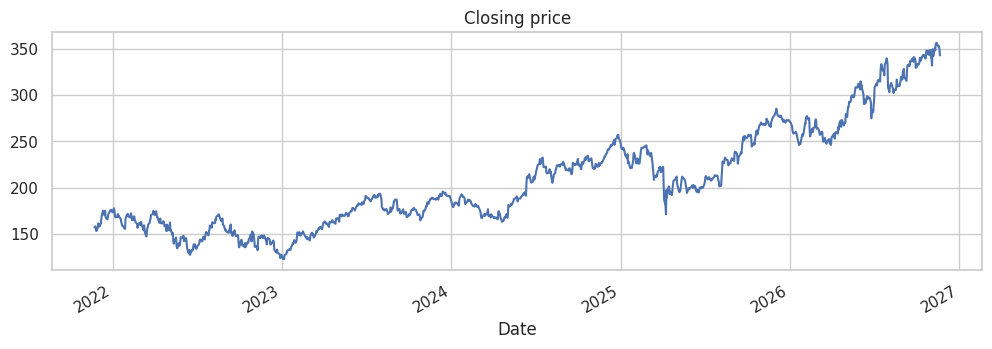

,MAE,RMSE,MAPE %
Naive,2.378,3.412,0.987
Moving average (5),4.147,5.633,1.710
Linear regression,2.494,3.501,1.037


In [ ]:
# !pip install yfinance        # uncomment in Colab if needed
try:
    import yfinance as yf
    stock = yf.download('AAPL', period='5y', interval='1d', auto_adjust=True, progress=False)['Close'].squeeze().dropna()      # change 'AAPL' to a company you like
    print(len(stock), 'daily closing prices'); stock.plot(figsize=(12, 3.5), title='Closing price'); plt.show()
    display(baselines_for(stock.values.astype(float)).round(3))
except Exception as e:
    print('Could not download stock data here:', type(e).__name__, '| skip this section or run it in Colab with internet access.')